# Tri-training and model selection under sampling bias

The two requested approaches produced a modest new best: **0.912393 validation sample-wise F1**, compared with the previous **0.910256**. Macro F1 rose from **0.780000 to 0.810444**. The winner combines the previous SVM and classical tri-training, with per-reason choices made on training folds. It remains below the requested **0.92735 validation target**. This small improvement does not establish statistical significance or a better Kaggle score.

All 78 validation rows remain outside fitting. The final train-plus-validation refit is deferred.

We screened 40 initial tri-training configurations and reranked prior configurations with training-only risk weights. Eleven diverse candidates were reevaluated on three fresh grouped five-fold splits. Follow-ups tested an exact no-teaching control, classical tri-training without added safeguards (four additional configurations), and per-reason combinations. Across these batches, eight frozen candidates were evaluated on validation. Follow-ups were informed by earlier results; each candidate's settings and combination mask were fixed from training-side evidence before its validation evaluation.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd
import matplotlib.pyplot as plt
root=Path.cwd()
summary=json.loads((root/'experiments/phase21-summary.json').read_text())
summary

{'tri_configurations_screened': 44,
 'initial_fresh_cv_configurations': 11,
 'fresh_cv_seeds': [20261107, 20261108, 20261109],
 'validation_candidates': 8,
 'best_tri_validation_f1': 0.9038461538461541,
 'guarded_tri_validation_f1': 0.882051282051282,
 'target_weighted_selection_validation_f1': 0.8696581196581196,
 'initial_reason_hybrid_validation_f1': 0.9017094017094018,
 'reason_hybrid_validation_f1': 0.9123931623931625,
 'exact_control_validation_f1': 0.8547008547008546,
 'incumbent_validation_f1': 0.9102564102564102,
 'current_validation_f1': 0.9123931623931625,
 'validation_improvement': 0.00213675213675224,
 'current_validation_macro_f1': 0.81044356609574,
 'selected_hybrid_ordinary_cv': 0.9174805378627034,
 'selected_hybrid_leave_group_out_cv': 0.9286624203821657,
 'incumbent_retained': False,
 'target_met': False,
 'validation_used_for_training': False,
 'final_train_plus_validation_refit_performed': False}

## Tri-training implementation

Each reason is a binary task with three bootstrapped classical learners. A learner receives pseudo-labels from its two peers only when they agree and the peer-error / sample-size update conditions permit an update. Updates within a round are simultaneous. True gold labels stay fixed.

Four committees were tested: three RBF SVMs; SVM/logistic/ridge; three RBF bandwidths; and RBF/polynomial/linear SVMs. Comparisons included pseudo-label weights 0.03, 0.1 and 1; conservative cross-fitted error floors; confidence filtering; pseudo-label mass caps; and no-teaching controls. KMeans cluster agreement downweights inconsistent pseudo-labels. Stratified bootstrapping keeps the rare class present.

The classical follow-up used ordinary bootstrap samples, unit pseudo-label weights, no cluster gate, and a fixed majority-vote decoder. Its selected committee combines an RBF SVM (C=1, gamma=0.001), logistic regression (C=0.3), and ridge classification (alpha=10), with class balancing and at most eight update rounds. Its standalone validation sample F1 is 0.903846.

These are explicit adaptations of [Zhou and Li's tri-training](https://www.lamda.nju.edu.cn/publication/tkde05.pdf). Weighted labels, cluster gates, confidence filters, and cross-fitted error floors do not automatically inherit its theoretical guarantees. Smoothed vote scores are heuristic values, not calibrated probabilities; threshold 0.5 preserves majority voting, and margin scores break ties if the multilabel decoder would otherwise be empty.

## Selection weights

The source contains 157 gold-status rows; the target is the feature distribution of all 1,171 training rows. No validation/test rows or reason-label values are used to estimate weights.

A logistic propensity model and a tree propensity model predict gold versus masked status using embeddings and year, with identical-embedding groups kept together in cross-fitting. Estimated risk weights are proportional to P(gold) / P(gold | features). They are clipped, normalized, and shrunk halfway toward uniform weights. Kernel mean matching provides a third estimate.

These weights change the scoring of held-out training predictions and therefore the selected model/decoder. They do not fit validation labels. Strong label-dependent selection, imperfect propensity estimates, and poor overlap mean that an unbiased target-risk guarantee is not justified. The weighting models' AUCs below measure prediction of **selection status**, not trial-reason classification.

In [2]:
weighting=json.loads((root/'experiments/phase21-weighting.json').read_text())
pd.DataFrame(weighting['diagnostics']).T

,domain_oof_auc,domain_oof_logloss,gold_propensity_quantiles,raw_weight_quantiles,clipped_fraction,gamma,ridge,optimizer_success,iterations,effective_sample_size,minimum,maximum,mean
logistic,0.910429,0.20861,"[0.002182, 0.073047, 0.554335, 0.949691, 0.99673]","[0.134513, 0.141176, 0.241864, 1.842297, 6.703...",0.471338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tree,0.936362,0.138829,"[0.010437, 0.032184, 0.936928, 0.940622, 0.941...","[0.142379, 0.142537, 0.143099, 4.165804, 6.703...",0.821656,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kmm,NaN,NaN,NaN,NaN,NaN,0.003,0.1,True,29,141.048948,0.6,2.149603,1.0
uniform,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,157.0,1.0,1.0,1.0
propensity_logistic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93.596773,0.634842,3.871055,1.0
propensity_tree,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,92.245975,0.611797,3.294933,1.0


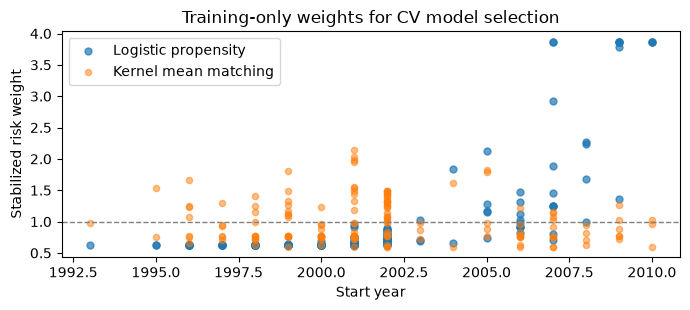

In [3]:
weights=pd.read_csv(root/'experiments/phase21-weights.csv')
train=pd.read_csv(root/'data/part1_train.csv')
plot=weights.merge(train[['ID','start_year']],on='ID',validate='one_to_one')
fig,ax=plt.subplots(figsize=(7,3.2))
ax.scatter(plot.start_year,plot.propensity_logistic,s=25,alpha=.7,label='Logistic propensity')
ax.scatter(plot.start_year,plot.kmm,s=20,alpha=.5,label='Kernel mean matching')
ax.axhline(1,color='gray',linestyle='--',linewidth=1)
ax.set(xlabel='Start year',ylabel='Stabilized risk weight',title='Training-only weights for CV model selection')
ax.legend()
fig.tight_layout()
(root/'figures').mkdir(exist_ok=True)
fig.savefig(root/'figures/current_phase21_weights.png',dpi=180)
plt.show()

## Frozen validation results

The adjusted selector favored an HDBSCAN-consensus logistic model with drug-name features. It had target-weighted training CV around 0.9276 but only 0.86966 on external validation. This is not a demonstrated generalization improvement.

The initial per-reason hybrid was selected from 32 combinations of the incumbent and tri-training predictions on fresh training folds. Training-only selection chose tri-training for Recruitment and the incumbent for the other reasons. It scored 0.90171 on validation and was rejected.

The initial bootstrap control matched the learner kinds but differed in aggregation and decoder. The exact ablation matches the initial tri-training winner's settings, including aggregation and its fixed decoder, with cross-teaching disabled. On that exact comparison, tri-training improves 0.85470 to 0.88205. The separately selected bootstrap control scored 0.88462. These initial candidates did not beat the incumbent.

Classical tri-training without the added safeguards scored 0.903846. Applying the unchanged hybrid selection rule to that candidate yielded the new best. The selector considered 32 masks on three fresh sets of grouped training folds, favored stability and robust weighted risk, and penalized extra switches. It chose **the previous SVM for Safety, Funding and Efficacy; tri-training for Recruitment and Other**. The mask and both decoders were frozen before validation. No per-reason choices came from validation errors.

The hybrid's mean repeated grouped five-fold F1 is **0.917481**. A subsequent leave-one-embedding-group-out audit of the fixed policy scored **0.928662**. Both are training-data development scores; neither is a validation or Kaggle score. The latter audit does not rerun the complete model-selection process inside each fold.

In [4]:
batches=['phase21','phase21b','phase21c','phase21d']
results=sum([json.loads((root/f'experiments/{b}-validation-results.json').read_text()) for b in batches],[])
rows=[dict(candidate=r['name'],ordinary_cv=r.get('ordinary_cv'),validation_f1=r['validation']['sample_f1'],validation_macro=r['validation']['macro_f1'],rule=r['rule']) for r in results]
pd.DataFrame(rows)

,candidate,ordinary_cv,validation_f1,validation_macro,rule
0,tri_ordinary_cv,0.913871,0.882051,0.774175,expected_f1
1,tri_target_weighted_cv,0.909413,0.854701,0.684471,t0.65
2,existing_target_weighted_cv + robust_weighting_cv,0.921373,0.869658,0.708371,t0.25
3,matched_no_teaching_control,0.904459,0.884615,0.723882,t0.55
4,training_selected_reason_hybrid,0.916490,0.901709,0.774175,t0.5
5,exact_no_teaching_ablation,0.905449,0.854701,0.743895,expected_f1
6,classical_tri_majority,0.911111,0.903846,0.805364,t0.5
7,classical_tri_reason_hybrid,0.917481,0.912393,0.810444,t0.5


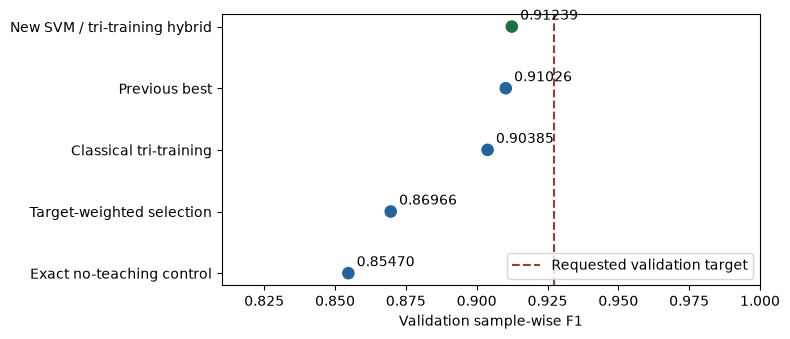

In [5]:
names=['New SVM / tri-training hybrid','Previous best','Classical tri-training','Target-weighted selection','Exact no-teaching control']
scores=[summary[k] for k in ['current_validation_f1','incumbent_validation_f1','best_tri_validation_f1','target_weighted_selection_validation_f1','exact_control_validation_f1']]
fig,ax=plt.subplots(figsize=(8,3.5))
ax.scatter(scores,np.arange(len(names)),s=65,color=['#197144']+['#2563a0']*4)
for i,s in enumerate(scores): ax.annotate(f'{s:.5f}',(s,i),xytext=(6,5),textcoords='offset points')
ax.axvline(.92735,color='#9b3e27',linestyle='--',label='Requested validation target')
ax.set(yticks=np.arange(len(names)),yticklabels=names,xlim=(.81,1),xlabel='Validation sample-wise F1')
ax.invert_yaxis();ax.legend(loc='lower right')
fig.tight_layout();fig.savefig(root/'figures/current_phase21_comparison.png',dpi=180)
plt.show()

## Integrity and artifacts

The current prediction file and frozen configuration now contain the new hybrid. The previous candidate is preserved under `predictions/checkpoints/pre_phase21_091026`. No train-plus-validation refit was performed. Every validation comparison is logged; this repeatedly used selection set is not a pristine test set. Kaggle performance remains unmeasured. No external trial data, extra labels or deep learning were used.

Source is embedded in notebook 04: `phase21.py`, `phase21_weights.py`, `phase21_select.py`, `phase21_hybrid.py`, `phase21_plain.py`, `phase21_classical_hybrid.py`, `phase21_fullsize_current.py` and `phase21_integrity.py`. Protocol, frozen weights, fold rankings, update diagnostics, predictions and results are under `experiments/phase21*`.

The final hybrid passed held-out-label perturbation, query-batch invariance, masked-duplicate exclusion and nonempty-output checks. Reproduction verifies raw-data hashes, all original gold labels and the exact submission checksum.

The weighting approach is motivated by [importance-weighted cross-validation](https://www.jmlr.org/papers/v8/sugiyama07a.html); its assumptions and limitations are stated above.

In [6]:
json.loads((root/'experiments/phase21-integrity-checks.json').read_text())

{'selected_config': {'model': 'tri_labelwise',
  'base': {'model': 'lowdensity_v2',
   'cluster_gate': True,
   'clusters': 10,
   'C': 1,
   'gamma': 0.001,
   'pseudo_weight': 0.03},
  'tri': {'model': 'tri_training',
   'committee': 'mixed',
   'cluster_gate': False,
   'pseudo_weight': 1.0,
   'aggregation': 'vote',
   'stratified_bootstrap': False},
  'base_rule': 't0.55',
  'tri_rule': 't0.5',
  'use_tri': [0, 0, 0, 1, 1]},
 'heldout_rows': 31,
 'selected_hybrid_holdout_label_invariance': True,
 'selected_hybrid_query_batch_invariance': True,
 'selected_hybrid_return_unlabeled_query_invariance': True,
 'matching_masked_embedding_duplicates_excluded': True,
 'all_predictions_binary_nonempty': True,
 'positive_normalized_risk_weights': True,
 'uniform_row_f1_matches_sklearn': True,
 'max_label_perturbation': 0.0,
 'max_batch_difference': 0.0,
 'validation_labels_used_for_training': 0,
 'refit_with_validation_performed': False,
 'source_sha256': {'phase21.py': '5d6b5d5c54f19943fba9a